In [1]:
# Loading libraries

import astropy
import os
import numpy as np
import pandas as pd
import matplotlib
import scipy
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table, QTable
from matplotlib import pyplot as plt
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
# vstack is used to concatenate tables
from astropy.table import vstack

In [2]:
alma_regions = Table.read("../alma_input/almaprops_2024_all_20250219.tab", format="ascii.ipac")
print(alma_regions[:2])
print("\n\n\n")

    ALMAGAL_ID           ORIG_ID        INTERNAL_ID ... FIT_FLAG OBS_SAMPLE
                                                    ...                    
----------------- --------------------- ----------- ... -------- ----------
AG010.1313-0.7687 HIGALBM10.1330-0.7710       46677 ...        -       near
AG010.1392-0.7831 HIGALBM10.1395-0.7833       46696 ...        -       near






In [3]:
spitzer_sources = Table.read("../output/spitzer_sources.tbl", format="ascii.ipac")
print(spitzer_sources[:2])
print("\n\n\n")

cntr_01  dist_x    pang_x   internal_id_01 ... color45_58 color45_80 color58_80
         arcsec     deg                    ...                                 
------- -------- ---------- -------------- ... ---------- ---------- ----------
      1 2.867081 -55.508188          46677 ...      0.471      0.367     -0.104
      1 4.406157  86.064855          46677 ...         --         --         --






In [6]:
alma_sources = pd.read_csv('../alma_input/7MTM2TM1_Core_catalogue_out_official_v3_run6Apr23+16Jan24_sn-5_may24_clump_cat.txt', comment='\\', skiprows=[2], delimiter='\s+')
print(alma_sources[6001:6004])
print("\n\n\n")

      ID               CLUMP          X          Y         RA        DEC  \
6001  22  G323.7399-00.2617B  386.92831  335.97809  232.93886 -56.514006   
6002  23  G323.7399-00.2617B  374.90641  340.99945  232.93932 -56.513900   
6003  20  G323.7399-00.2617B  355.04385  326.97879  232.94008 -56.514196   

           GLON      GLAT     F_PEAK         S/N  ...  Back_onpeak_jybm  \
6001  323.73984 -0.262544  1489.3764   31.570764  ...          0.004688   
6002  323.74011 -0.262602  6066.5668  128.594859  ...          0.006919   
6003  323.74028 -0.263085  1283.1450   27.199214  ...          0.011580   

            Rcore  Surfd_core        n(H2)              AG_ID  \
6001   984.988790    3.902623   63200000.0  AG323.7408-0.2633   
6002  1044.259595   15.896265  243000000.0  AG323.7408-0.2633   
6003   973.958180    3.362233   55100000.0  AG323.7408-0.2633   

                 ORIG_ID  RADIO_INFO  RADIO_MATCH  Surfd_nd VLSR_clump  
6001  G323.7399-00.2617B           1            0      1.58 

In [8]:
def source_match(region):

    match_table_local = QTable(
    names=['region_id','alma_source','spitzer_source','alma_ra','alma_dec','spitzer_ra','spitzer_dec','separation_arcsec'],
    units=[None, None, None, 'deg', 'deg', 'deg', 'deg', 'arcsec deg'],
    dtype=['str','int64','str','float64','float64','float64','float64','float64']
    )

    spitzer_sources_cut = spitzer_sources[spitzer_sources["internal_id_01"] == str(region["INTERNAL_ID"])]
    alma_sources_cut = alma_sources[alma_sources["CLUMP"] == str(region["INTERNAL_ID"])].reset_index(drop=True)


    for alma_index in range(len(alma_sources_cut)):
        
        source_coords = SkyCoord(alma_sources_cut["RA"][alma_index], alma_sources_cut["DEC"][alma_index], unit=(u.deg, u.deg), frame="icrs")
        radius = 0.6*u.arcsec+0.25*u.arcsec # Spitzer resolution + ALMA resolution (assuming 0.25" for ALMA)
        spitzer_coords = SkyCoord(spitzer_sources_cut["ra"], spitzer_sources_cut["dec"], unit=(u.deg, u.deg), frame="icrs")
        seps = source_coords.separation(spitzer_coords)
        for spitzer_index in range(len(spitzer_sources_cut)):
            if seps[spitzer_index] < radius:
                match_table_local.add_row([alma_sources_cut["CLUMP"][alma_index], (alma_index+1), spitzer_sources_cut["designation"][spitzer_index], 
                                     source_coords.ra.deg*u.deg, source_coords.dec.deg*u.deg,spitzer_sources_cut["ra"][spitzer_index]*u.deg, spitzer_sources_cut["dec"][spitzer_index]*u.deg,(seps[spitzer_index]*3600)*u.arcsec])
    return match_table_local


In [9]:
match_table = QTable(
    names=['region_id','alma_source','spitzer_source','alma_ra','alma_dec','spitzer_ra','spitzer_dec','separation_arcsec'],
    units=[None, None, None, 'deg', 'deg', 'deg', 'deg', 'arcsec deg'],
    dtype=['str','int64','str','float64','float64','float64','float64','float64']
)


test_regions = len(alma_regions) # Set this to a smaller number for testing, e.g., 10 or 20
regions_subset = alma_regions[:test_regions]



with Pool(cpu_count()) as pool:
    results = tqdm(pool.map(source_match, regions_subset), total=len(regions_subset))

for result in results:
    match_table = vstack([match_table, result])

print('done!')


100%|██████████| 1017/1017 [00:00<00:00, 1135.16it/s]

done!


In [10]:
match_table['separation_arcsec'].format = "{:.2E}"

print(match_table)

match_table.write("../output/match_table.tbl", format="ascii.ipac", overwrite=True)

    region_id     alma_source ... spitzer_dec  separation_arcsec 
                              ...     deg          arcsec deg    
----------------- ----------- ... ----------- -------------------
            47184           2 ...  -20.191348  0.6168242796454642
            49005           3 ...  -19.811121  0.2851707572111167
G010.8856+00.1221           2 ...  -19.456672   0.372521157186798
            50555           6 ...  -19.597059  0.4282517597218486
            51554           4 ...  -18.709532 0.24499245088841778
            51554           5 ...  -18.708429 0.49630287338405427
            52831           1 ...  -18.949053  0.7828677778564165
            53795           1 ...  -18.694229  0.7414087104302064
            53795           9 ...  -18.691359   0.282948030239085
              ...         ... ...         ...                 ...
           876288          22 ...  -39.158065  0.4460129709053724
           877689           1 ...  -38.831309 0.48251643891930873
          

---

count = 0

test_regions = 20
source_count = 0

for region in alma_regions[:test_regions]: # Just for the first 100 regions

    count +=1
    spitzer_sources_cut = spitzer_sources[spitzer_sources["internal_id_01"] == str(region["INTERNAL_ID"])]
    alma_sources_cut = alma_sources[alma_sources["CLUMP"] == str(region["INTERNAL_ID"])].reset_index(drop=True)

    if source_count > 0:   
        plt.figure(figsize=(5, 5))

    source_count = 0


    for alma_index in range(len(alma_sources_cut)):
        source_coords = SkyCoord(alma_sources_cut["RA"][alma_index], alma_sources_cut["DEC"][alma_index], unit=(u.deg, u.deg), frame="icrs")

        radius = 1*u.arcsec

        for spitzer_clump in spitzer_sources_cut:
            spitzer_coords = SkyCoord(spitzer_clump["ra"], spitzer_clump["dec"], unit=(u.deg, u.deg), frame="icrs")

            if source_coords.separation(spitzer_coords) < radius:
                source_count += 1
                plt.scatter(spitzer_coords.ra.deg, spitzer_coords.dec.deg, color="blue", label="Spitzer Source",alpha=0.5)
                plt.scatter(source_coords.ra.deg, source_coords.dec.deg, color="red", label="ALMA Source",alpha=0.5)


    print(f"progress: {count}/{len(alma_sources[:test_regions])}", end="\r")

    plt.title(f"Region {region['INTERNAL_ID']}")

    g = SkyCoord(region["GLON"], region["GLAT"], unit=(u.deg, u.deg), frame="galactic").icrs

    plt.ylim(g.dec.deg - 1./120., g.dec.deg + 1./120.)
    plt.xlim(g.ra.deg - 1./120., g.ra.deg + 1./120.)
    plt.ylabel("Declination (deg)")
    plt.xlabel("Right Ascension (deg)") 
    if source_count > 0:   
        plt.show()
    print("\n")


In [11]:
def plot_separation_histogram(match_table):
    plt.figure(figsize=(8, 6))
    plt.hist(match_table['separation_arcsec'], bins=20, color='skyblue', edgecolor='black')
    plt.title('Distribution of Separations Between ALMA and Spitzer Sources')
    plt.xlabel('Separation (arcseconds)')
    plt.ylabel('Number of Matches')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

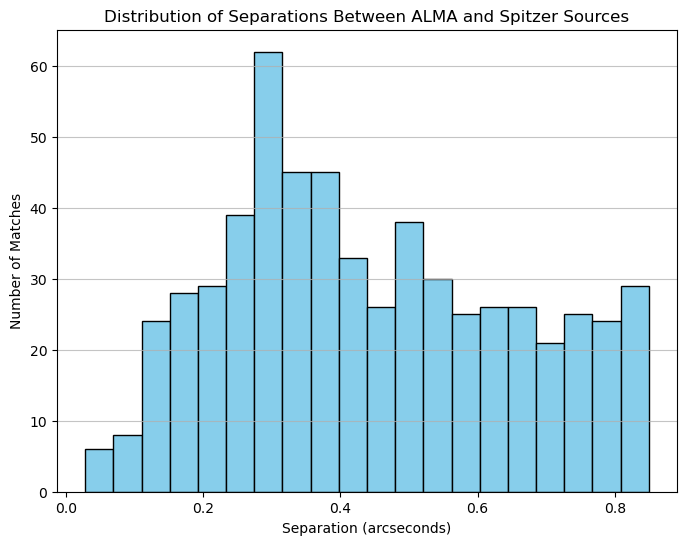

In [12]:
plot_separation_histogram(match_table)

In [21]:
def plot_source_matches(match_table,region_id):
    
    region_matches = match_table[match_table['region_id'] == region_id]
    
    for alma_source in set(region_matches['alma_source']):
        #plt.figure(figsize=(5, 5))
        _, ax = plt.subplots()

        alma_source_matches = region_matches[region_matches['alma_source'] == alma_source]
        radius = 0.6*u.arcsec+0.25*u.arcsec # Spitzer resolution + ALMA resolution (assuming 0.25" for ALMA)
        ax.scatter([0], [0], color="red", label="ALMA Source",alpha=1)
        ax.scatter((alma_source_matches['spitzer_ra']-alma_source_matches['alma_ra'])*np.cos(np.deg2rad(alma_source_matches['alma_dec']))*3600, (alma_source_matches['spitzer_dec']-alma_source_matches['alma_dec'])*3600, color="blue", label="Spitzer Source",alpha=0.5)
        circle_total = plt.Circle((0, 0), radius.to_value(u.arcsec), color='black', fill=False, linestyle='--', label='Matching Radius (0.85 arcsec)')
        circle_alma = plt.Circle((0, 0), 0.25, color='red', fill=False, linestyle='-', label='ALMA Resolution (0.25 arcsec)')
        #circle_spitzer = plt.Circle(((alma_source_matches['spitzer_ra']-alma_source_matches['alma_ra'])*np.cos(np.deg2rad(alma_source_matches['alma_dec']))*3600, (alma_source_matches['spitzer_dec']-alma_source_matches['alma_dec'])*3600), 0.6, color='blue', fill=False, linestyle='-', label='Spitzer Resolution (0.6 arcsec)')
        ax.add_patch(circle_alma)
        #ax.add_patch(circle_spitzer)
        ax.add_patch(circle_total)

        ax.set_title(f"Source {alma_source} in Region {region_id}")


        ax.set_ylim(-1, 1)
        ax.set_xlim(-1, 1)
        ax.set_ylabel("Declination (arcsec)")
        ax.set_xlabel("Right Ascension (arcsec)") 
        ax.set_aspect('equal', adjustable='box')
        plt.show()

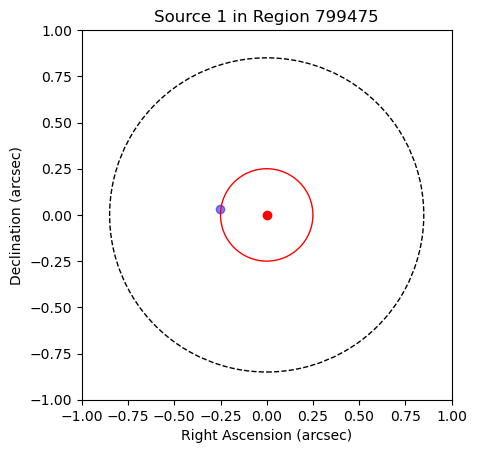

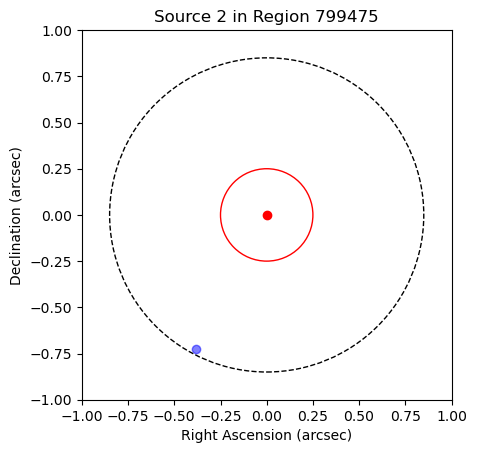

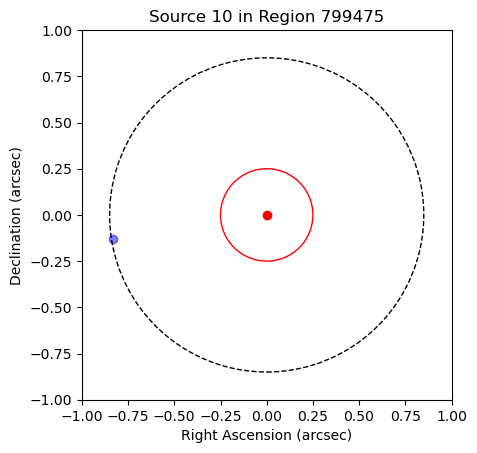

In [22]:
test_sources = 10

for region_id in list(set(match_table['region_id']))[:test_sources]:
    if len(match_table[match_table['region_id'] == region_id]["spitzer_source"]) > 2:
        plot_source_matches(match_table, region_id)

In [15]:
print(match_table['region_id'])
#make unique list of region ids
unique_region_ids = set(match_table['region_id'])
print(unique_region_ids)

    region_id    
-----------------
            47184
            49005
G010.8856+00.1221
            50555
            51554
            51554
            52831
            53795
            53795
            53869
              ...
           876288
           877689
           877689
           880433
           880433
           880433
           880433
           881427
           881644
           886687
Length = 589 rows
{np.str_('G340.0543-00.2437D'), np.str_('136060'), np.str_('779984'), np.str_('62842'), np.str_('810498'), np.str_('G334.7302+00.0052'), np.str_('805162'), np.str_('836078'), np.str_('799475'), np.str_('822761'), np.str_('92392'), np.str_('115961'), np.str_('694823'), np.str_('G018.3706-00.3818'), np.str_('112687'), np.str_('810788'), np.str_('876288'), np.str_('720116'), np.str_('131655'), np.str_('126186'), np.str_('792437'), np.str_('G309.9796+00.5496'), np.str_('705424'), np.str_('139543'), np.str_('784722'), np.str_('765015'), np.str_('886687'), np.str_('11

In [16]:
plot_region(alma_regions[alma_regions["INTERNAL_ID"] == "47184"])
print(alma_regions[alma_regions["INTERNAL_ID"] == "47184"])

NameError: name 'plot_region' is not defined